# Selective deviations from fixed ¼×

This analysis uses all 72 saved seed–checkpoint pairs. At each horizon, advantage is the measured O3 score under ¼× minus the score under the candidate action. Positive advantage favors the candidate. The primary minimum gain is **δ = 0.01 O3 units**, the reference gap from the preceding analysis. Each selector controls one initial update, followed by the same fixed ¼× continuation.

## Regret and intervention at the prespecified thresholds

| Horizon | Selector | Interventions | Mean regret | Mean gain vs ¼× | 95% paired interval | Meaningful / harmful interventions |
| --- | --- | --- | --- | --- | --- | --- |
 | 0 | Fixed ¼× | 0/72 | 0.02533 | +0.00000 | [+0.00000, +0.00000] | 0 / 0 | 
 | 0 | Original Lasso O3 | 49/72 | 0.01632 | +0.00902 | [+0.00276, +0.01524] | 30 / 11 | 
 | 0 | Advantage classifier | 59/72 | 0.01060 | +0.01474 | [+0.00126, +0.02793] | 38 / 6 | 
 | 0 | Confidence-gated | 1/72 | 0.02478 | +0.00055 | [+0.00000, +0.00166] | 1 / 0 | 
 | 0 | Oracle with minimum gap | 50/72 | 0.00172 | +0.02361 | [+0.01534, +0.03405] | 50 / 0 | 
 | 96 | Fixed ¼× | 0/72 | 0.00717 | +0.00000 | [+0.00000, +0.00000] | 0 / 0 | 
 | 96 | Original Lasso O3 | 49/72 | 0.01258 | -0.00541 | [-0.01028, -0.00134] | 2 / 29 | 
 | 96 | Advantage classifier | 1/72 | 0.00781 | -0.00064 | [-0.00191, +0.00000] | 0 / 1 | 
 | 96 | Confidence-gated | 0/72 | 0.00717 | +0.00000 | [+0.00000, +0.00000] | 0 / 0 | 
 | 96 | Oracle with minimum gap | 7/72 | 0.00155 | +0.00562 | [+0.00091, +0.01273] | 7 / 0 | 
 | 1000 | Fixed ¼× | 0/72 | 0.07065 | +0.00000 | [+0.00000, +0.00000] | 0 / 0 | 
 | 1000 | Original Lasso O3 | 49/72 | 0.09829 | -0.02764 | [-0.09022, +0.02402] | 14 / 25 | 
 | 1000 | Advantage classifier | 6/72 | 0.08477 | -0.01412 | [-0.03884, -0.00032] | 0 / 5 | 
 | 1000 | Confidence-gated | 0/72 | 0.07065 | +0.00000 | [+0.00000, +0.00000] | 0 / 0 | 
 | 1000 | Oracle with minimum gap | 28/72 | 0.00123 | +0.06942 | [+0.03186, +0.11313] | 28 / 0 | 

Regret is relative to the unrestricted measured oracle. Mean gain is relative to fixed ¼×. A harmful intervention has negative measured advantage. A meaningful intervention exceeds δ. Intervals are descriptive paired bootstrap intervals with the three seeds at each arrival sampled together. They condition on the saved trajectories and out-of-fold decisions.

The lines sweep the classifier probability and lower-bound thresholds over the held-out predictions. Markers show the prespecified policy settings. The oracle curve starts with the largest measured gains and ends when every gain above δ has been taken. The confidence-gated square surrounds the default marker when the two policies coincide.


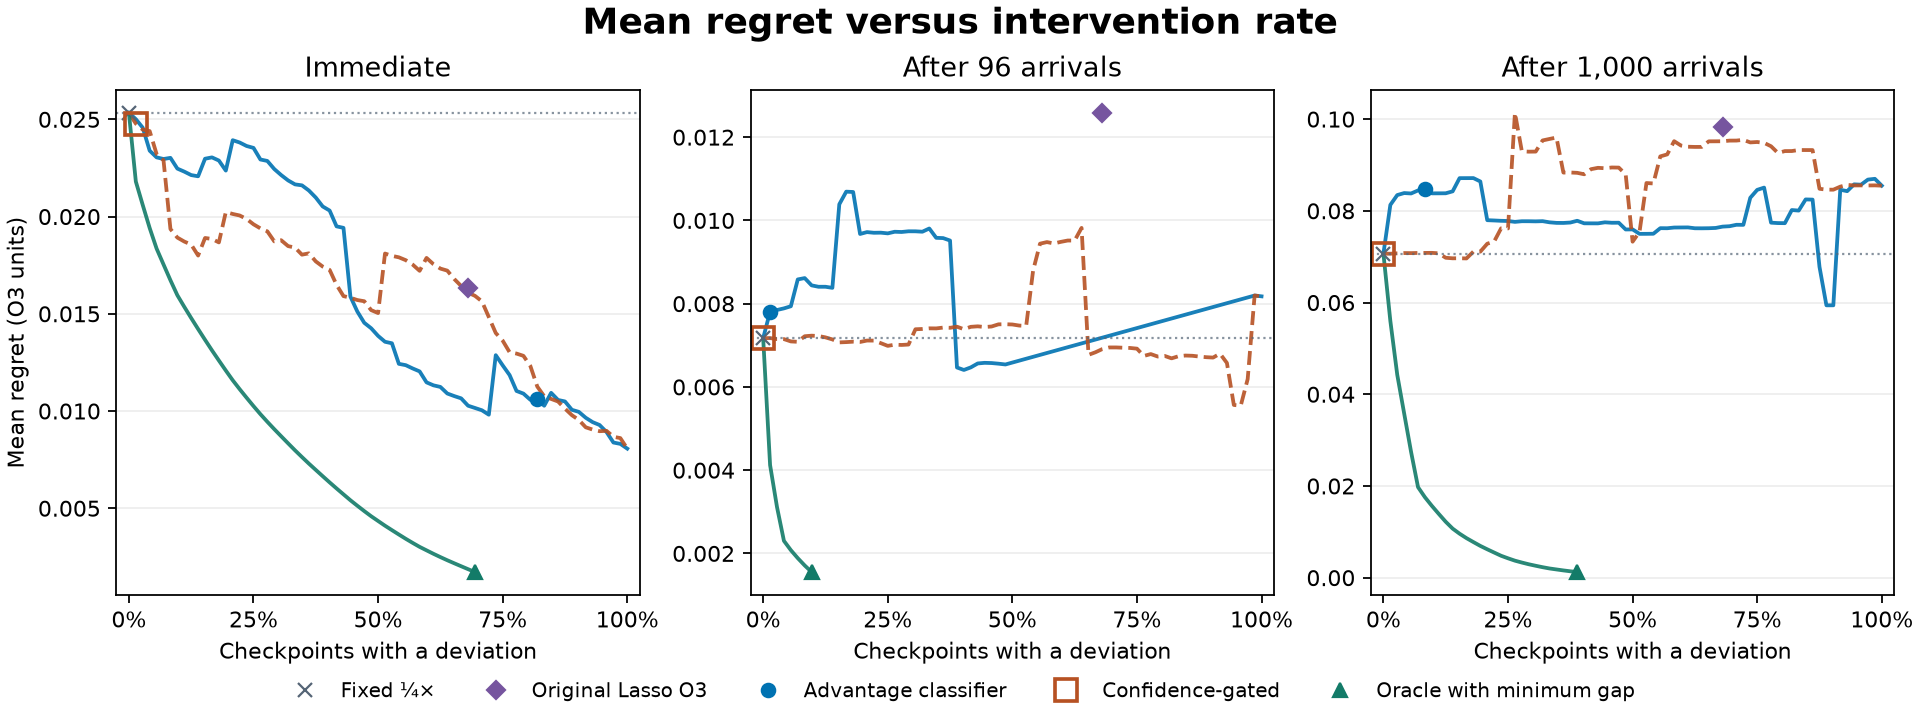

## Predicting meaningful gains

Six contiguous blocks of four arrival positions are held out in turn, with all three seeds held out together. Each fold uses 10 other positions for fitting and 10 for calibration, interleaved over the remaining stream. This is a retrospective cross-fit across blocks. All features are available at the checkpoint. The six inputs are the four pre-action measurements and the two original Lasso forecast differences from ¼× for current-image loss and RankMe. Inputs use the saved calibration scales and a training-fold standardization.

Each horizon and alternative gets a regularized logistic model for the binary target A > δ. The classifier proposes the alternative with the higher probability and intervenes if that probability exceeds 0.5. The confidence gate uses the same proposed action and a ridge estimate of its advantage. It subtracts a one-sided split-conformal overprediction allowance calibrated on the proposed actions, using the largest error across seeds per arrival. It intervenes only if that lower predictive bound exceeds δ. At 90% nominal coverage with 10 calibration positions, the allowance uses the largest calibration error. The nominal calibration assumes exchangeable arrival groups. Observed coverage is shown for these stream blocks.

| Horizon | Candidate | Positive labels | Positive rate | Out-of-fold average precision | Arrival-level lower-bound coverage |
| --- | --- | --- | --- | --- | --- |
 | 0 | Skip | 3 | 4.2% | 0.047 | 87.5% | 
 | 0 | 1× | 47 | 65.3% | 0.687 | 87.5% | 
 | 96 | Skip | 3 | 4.2% | 0.093 | 100.0% | 
 | 96 | 1× | 4 | 5.6% | 0.150 | 100.0% | 
 | 1000 | Skip | 20 | 27.8% | 0.225 | 95.8% | 
 | 1000 | 1× | 18 | 25.0% | 0.250 | 95.8% | 

Average precision evaluates the binary predictions across held-out checkpoints. The positive rate is the no-skill reference. Arrival-level coverage requires the lower bound to hold across all three seeds.

## Minimum-gap oracle sensitivity

| Horizon | Minimum gain δ | Oracle interventions | Mean oracle gain vs ¼× |
| --- | --- | --- | --- |
 | 0 | 0.001 | 70/72 | 0.02532 | 
 | 0 | 0.005 | 65/72 | 0.02510 | 
 | 0 | 0.010 | 50/72 | 0.02361 | 
 | 0 | 0.020 | 33/72 | 0.02020 | 
 | 0 | 0.050 | 7/72 | 0.00938 | 
 | 96 | 0.001 | 38/72 | 0.00707 | 
 | 96 | 0.005 | 12/72 | 0.00614 | 
 | 96 | 0.010 | 7/72 | 0.00562 | 
 | 96 | 0.020 | 3/72 | 0.00487 | 
 | 96 | 0.050 | 3/72 | 0.00487 | 
 | 1000 | 0.001 | 45/72 | 0.07057 | 
 | 1000 | 0.005 | 35/72 | 0.07017 | 
 | 1000 | 0.010 | 28/72 | 0.06942 | 
 | 1000 | 0.020 | 23/72 | 0.06836 | 
 | 1000 | 0.050 | 17/72 | 0.06587 | 
